## Global Conflicts Analysis

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Load and Inspect the dataset

In [3]:
df = pd.read_csv("../data/global_conflicts_dataset.csv")
df.head(10)

,Country_A,Country_B,Conflict_Type,Year,Duration_Days,Military_Deaths_A,Military_Deaths_B,Civilian_Deaths,Economic_Loss_USD_Billions,Temperature_Avg_C,...,Naval_Battles,Sanctions,Refugees_Millions,Ceasefire,Outcome,Latitude,Longitude,Climate_Zone,Resource_Dispute,UN_Involvement
0,France,France,Cold Conflict,2020,1829,33197,41305,50364,176.45,8.2,...,104,Yes,6.68,No,Victory_A,88.811,101.020,Temperate,Land,Yes
1,India,Japan,Cold Conflict,2013,1234,26773,10526,176846,435.83,24.8,...,87,Yes,14.51,Yes,Stalemate,55.878,78.502,Polar,Water,No
2,Israel,USA,Civil War,1970,1982,17256,7604,17280,154.50,17.3,...,9,No,1.63,No,Stalemate,29.263,144.680,Tropical,Water,No
3,Turkey,Australia,Proxy War,2021,1754,1745,33468,92279,273.20,12.3,...,15,No,7.23,No,Victory_A,-22.281,-147.397,Polar,Water,No
4,Australia,France,War,2012,753,29149,40672,72545,351.35,31.1,...,22,Yes,19.65,No,Victory_A,17.638,169.360,Temperate,Land,No
5,Brazil,Brazil,Civil War,2013,886,9915,46117,101440,499.96,7.0,...,46,Yes,15.71,No,Victory_B,68.465,-169.618,Tropical,Oil,Yes
6,Israel,Ukraine,Civil War,1969,464,1948,38405,173852,217.70,-0.1,...,11,Yes,11.44,Yes,Victory_A,-35.014,-58.427,Tropical,Oil,No
7,UK,Iran,Civil War,1957,712,34429,32194,91987,214.10,17.4,...,155,No,1.24,Yes,Stalemate,-84.483,-149.462,Arid,Oil,Yes
8,France,Russia,Cold Conflict,2007,728,33641,14785,113773,421.31,18.1,...,76,Yes,0.29,Yes,Victory_A,-31.107,-161.577,Tropical,NaN,Yes
9,Canada,India,Skirmish,1995,717,7411,8824,3373,402.77,9.8,...,17,Yes,2.10,No,Stalemate,82.841,167.300,Arid,Oil,No


In [4]:
df.columns

Index(['Country_A', 'Country_B', 'Conflict_Type', 'Year', 'Duration_Days',
       'Military_Deaths_A', 'Military_Deaths_B', 'Civilian_Deaths',
       'Economic_Loss_USD_Billions', 'Temperature_Avg_C', 'Rainfall_mm',
       'Terrain_Type', 'Population_A_Millions', 'Population_B_Millions',
       'GDP_A_Billions', 'GDP_B_Billions', 'Alliance_A', 'Alliance_B',
       'Weapons_Used', 'Air_Strikes', 'Naval_Battles', 'Sanctions',
       'Refugees_Millions', 'Ceasefire', 'Outcome', 'Latitude', 'Longitude',
       'Climate_Zone', 'Resource_Dispute', 'UN_Involvement'],
      dtype='object')

In [5]:
df.dtypes

Country_A                      object
Country_B                      object
Conflict_Type                  object
Year                            int64
Duration_Days                   int64
Military_Deaths_A               int64
Military_Deaths_B               int64
Civilian_Deaths                 int64
Economic_Loss_USD_Billions    float64
Temperature_Avg_C             float64
Rainfall_mm                   float64
Terrain_Type                   object
Population_A_Millions         float64
Population_B_Millions         float64
GDP_A_Billions                float64
GDP_B_Billions                float64
Alliance_A                     object
Alliance_B                     object
Weapons_Used                   object
Air_Strikes                     int64
Naval_Battles                   int64
Sanctions                      object
Refugees_Millions             float64
Ceasefire                      object
Outcome                        object
Latitude                      float64
Longitude   

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Country_A                   3000 non-null   object 
 1   Country_B                   3000 non-null   object 
 2   Conflict_Type               3000 non-null   object 
 3   Year                        3000 non-null   int64  
 4   Duration_Days               3000 non-null   int64  
 5   Military_Deaths_A           3000 non-null   int64  
 6   Military_Deaths_B           3000 non-null   int64  
 7   Civilian_Deaths             3000 non-null   int64  
 8   Economic_Loss_USD_Billions  3000 non-null   float64
 9   Temperature_Avg_C           3000 non-null   float64
 10  Rainfall_mm                 3000 non-null   float64
 11  Terrain_Type                3000 non-null   object 
 12  Population_A_Millions       3000 non-null   float64
 13  Population_B_Millions       3000 

In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Country_A,3000,15,USA,224,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country_B,3000,15,India,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Conflict_Type,3000,5,Skirmish,627,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,3000.0,NaN,NaN,NaN,1987.338,21.766006,1950.0,1968.0,1987.0,2007.0,2024.0
Duration_Days,3000.0,NaN,NaN,NaN,1003.734667,568.221869,2.0,529.0,999.0,1493.0,1999.0
Military_Deaths_A,3000.0,NaN,NaN,NaN,24423.385,14129.940099,105.0,12292.0,23889.0,36801.0,49995.0
Military_Deaths_B,3000.0,NaN,NaN,NaN,24959.623333,14345.873994,119.0,12768.25,24270.0,37424.5,49992.0
Civilian_Deaths,3000.0,NaN,NaN,NaN,100151.649333,57927.462774,68.0,49719.5,100106.5,149615.75,199972.0
Economic_Loss_USD_Billions,3000.0,NaN,NaN,NaN,253.68445,142.903418,0.23,132.905,257.58,374.8975,499.96
Temperature_Avg_C,3000.0,NaN,NaN,NaN,12.928667,13.094564,-10.0,1.7,13.0,24.2,35.0


#### Date Quality

In [8]:
df[['Country_A', 'Country_B', 'Year']].drop_duplicates().head(20)

,Country_A,Country_B,Year
0,France,France,2020
1,India,Japan,2013
2,Israel,USA,1970
3,Turkey,Australia,2021
4,Australia,France,2012
5,Brazil,Brazil,2013
6,Israel,Ukraine,1969
7,UK,Iran,1957
8,France,Russia,2007
9,Canada,India,1995


In [9]:
df.isna().sum().sort_values(ascending=False)

Alliance_B                    992
Alliance_A                    983
Resource_Dispute              745
Conflict_Type                   0
Country_A                       0
Country_B                       0
Military_Deaths_B               0
Civilian_Deaths                 0
Economic_Loss_USD_Billions      0
Temperature_Avg_C               0
Rainfall_mm                     0
Year                            0
Duration_Days                   0
Military_Deaths_A               0
Population_B_Millions           0
Population_A_Millions           0
Terrain_Type                    0
GDP_B_Billions                  0
Weapons_Used                    0
Air_Strikes                     0
Naval_Battles                   0
GDP_A_Billions                  0
Sanctions                       0
Refugees_Millions               0
Outcome                         0
Ceasefire                       0
Latitude                        0
Longitude                       0
Climate_Zone                    0
UN_Involvement

In [10]:
missing_values_percent = df.isna().mean() * 100
missing_values_percent.sort_values(ascending=False)

Alliance_B                    33.066667
Alliance_A                    32.766667
Resource_Dispute              24.833333
Conflict_Type                  0.000000
Country_A                      0.000000
Country_B                      0.000000
Military_Deaths_B              0.000000
Civilian_Deaths                0.000000
Economic_Loss_USD_Billions     0.000000
Temperature_Avg_C              0.000000
Rainfall_mm                    0.000000
Year                           0.000000
Duration_Days                  0.000000
Military_Deaths_A              0.000000
Population_B_Millions          0.000000
Population_A_Millions          0.000000
Terrain_Type                   0.000000
GDP_B_Billions                 0.000000
Weapons_Used                   0.000000
Air_Strikes                    0.000000
Naval_Battles                  0.000000
GDP_A_Billions                 0.000000
Sanctions                      0.000000
Refugees_Millions              0.000000
Outcome                        0.000000


##### Investigate the missingness and its association with conflict types

After identifying columns having missing values, the distribution of
missing values is examined across conflict types.

The purpose is to determine whether missingness appears to be concentrated
within particular groups rather than occurring uniformly across the dataset.

In [11]:
pd.crosstab(
    df['Conflict_Type'],
    df['Alliance_A'].isna(),
    normalize='index'
)

Alliance_A,False,True
Conflict_Type,,
Civil War,0.671692,0.328308
Cold Conflict,0.698980,0.301020
Proxy War,0.660225,0.339775
Skirmish,0.657097,0.342903
War,0.675485,0.324515


In [12]:
pd.crosstab(
    df['Conflict_Type'],
    df['Resource_Dispute'].fillna('Missing'),
    normalize='index'
)

Resource_Dispute,Land,Missing,Oil,Water
Conflict_Type,,,,
Civil War,0.249581,0.242881,0.252931,0.254606
Cold Conflict,0.251701,0.239796,0.255102,0.253401
Proxy War,0.243156,0.276973,0.239936,0.239936
Skirmish,0.253589,0.232855,0.272727,0.240829
War,0.243386,0.248677,0.257496,0.250441


#### Numerical Variables

In [13]:
numeric_conflict = [
    'Duration_Days',
    'Military_Deaths_A',
    'Military_Deaths_B',
    'Civilian_Deaths',
    'Economic_Loss_USD_Billions',
    'Air_Strikes',
    'Naval_Battles',
    'Refugees_Millions',
]
df[numeric_conflict].describe().T

,count,mean,std,min,25%,50%,75%,max
Duration_Days,3000.0,1003.734667,568.221869,2.00,529.0000,999.000,1493.0000,1999.00
Military_Deaths_A,3000.0,24423.385000,14129.940099,105.00,12292.0000,23889.000,36801.0000,49995.00
Military_Deaths_B,3000.0,24959.623333,14345.873994,119.00,12768.2500,24270.000,37424.5000,49992.00
Civilian_Deaths,3000.0,100151.649333,57927.462774,68.00,49719.5000,100106.500,149615.7500,199972.00
Economic_Loss_USD_Billions,3000.0,253.684450,142.903418,0.23,132.9050,257.580,374.8975,499.96
Air_Strikes,3000.0,2489.252000,1448.823011,0.00,1228.7500,2457.000,3738.2500,4999.00
Naval_Battles,3000.0,98.849667,58.377493,0.00,47.0000,99.000,151.0000,199.00
Refugees_Millions,3000.0,10.082663,5.784529,0.00,5.1275,10.155,15.1100,20.00


In [14]:
df[numeric_conflict].skew().sort_values(ascending=False)

Military_Deaths_A             0.062117
Military_Deaths_B             0.044670
Air_Strikes                   0.019261
Naval_Battles                -0.007263
Duration_Days                -0.009647
Civilian_Deaths              -0.013887
Refugees_Millions            -0.034220
Economic_Loss_USD_Billions   -0.049154
dtype: float64

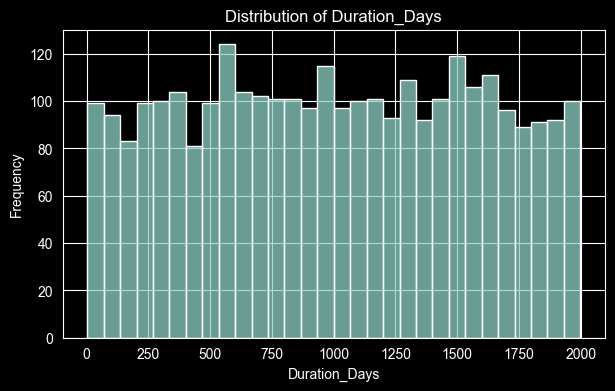

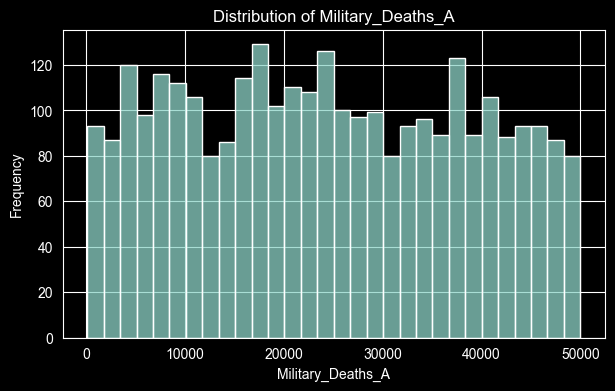

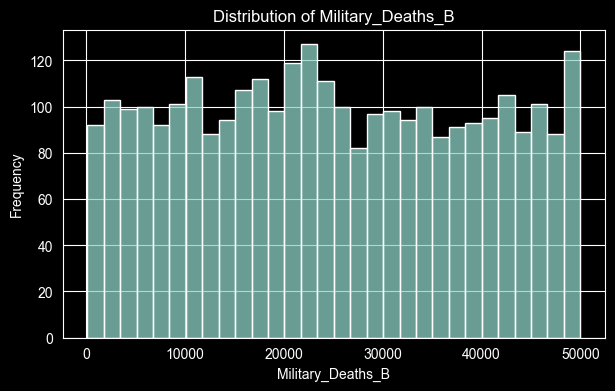

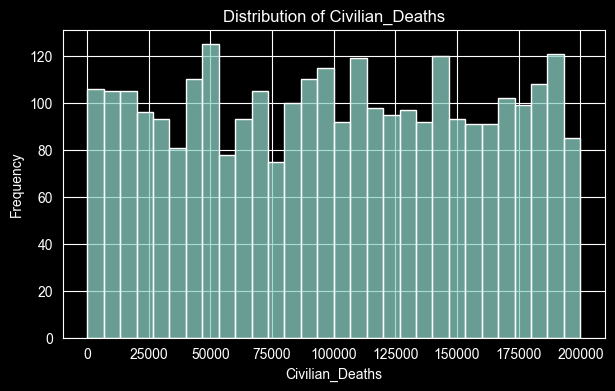

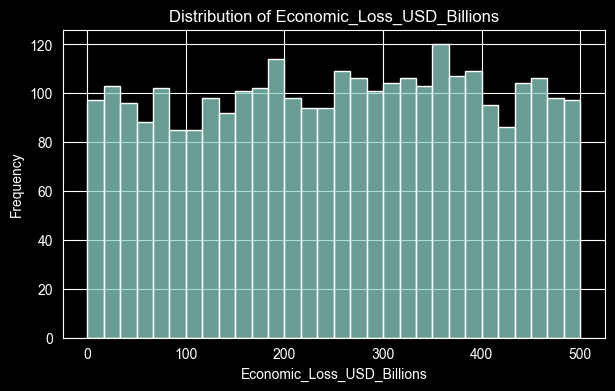

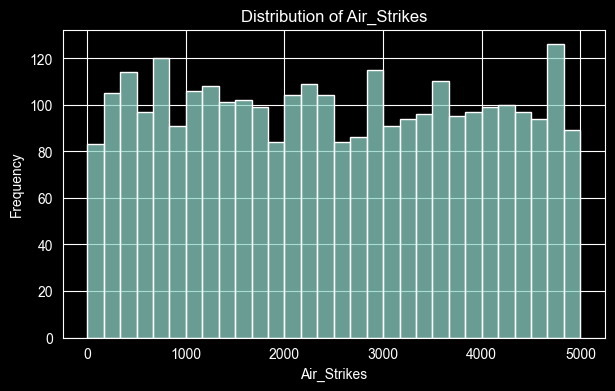

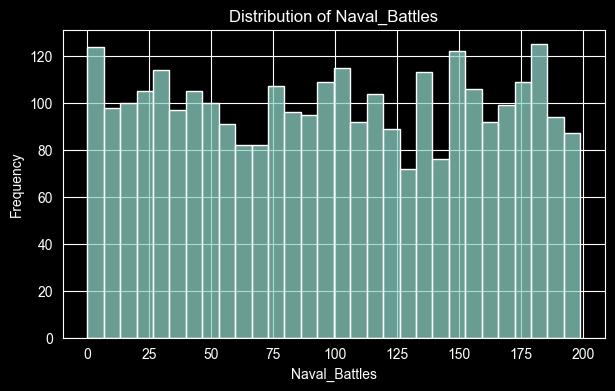

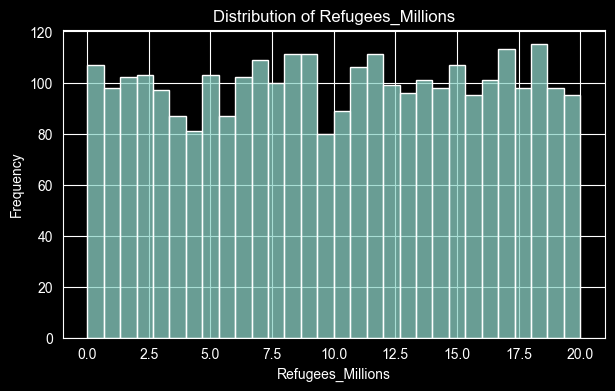

In [15]:
for col in numeric_conflict:
    plt.figure(figsize=(7,4))
    sns.histplot(df[col], bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

#### Categorical and Temporal Variables

In [16]:
categorical_vars = [
    'Conflict_Type',
    'Terrain_Type',
    'Climate_Zone',
    'Outcome'
]

for col in categorical_vars:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- Conflict_Type ---
Conflict_Type
Skirmish         627
Proxy War        621
Civil War        597
Cold Conflict    588
War              567
Name: count, dtype: int64

--- Terrain_Type ---
Terrain_Type
Forest      633
Plains      611
Urban       598
Mountain    591
Desert      567
Name: count, dtype: int64

--- Climate_Zone ---
Climate_Zone
Polar        790
Tropical     771
Arid         737
Temperate    702
Name: count, dtype: int64

--- Outcome ---
Outcome
Victory_A    1003
Victory_B    1002
Stalemate     995
Name: count, dtype: int64


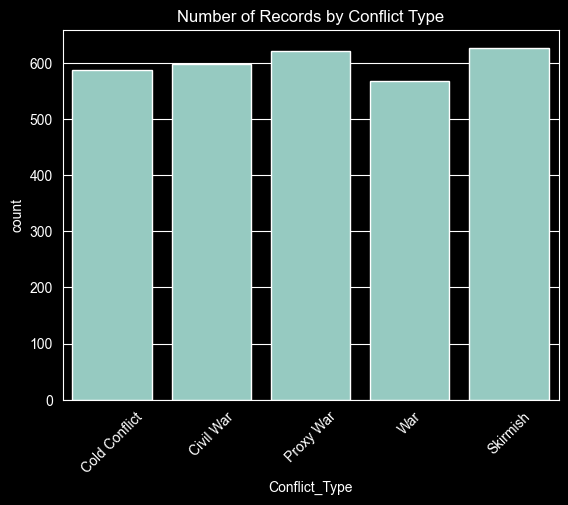

In [17]:
sns.countplot(data=df, x='Conflict_Type')
plt.xticks(rotation=45)
plt.title('Number of Records by Conflict Type')
plt.show()

In [18]:
df['Year'].describe()
df['Year'].value_counts().sort_index()

Year
1950    39
1951    47
1952    45
1953    34
1954    31
        ..
2020    46
2021    41
2022    45
2023    40
2024    39
Name: count, Length: 75, dtype: int64

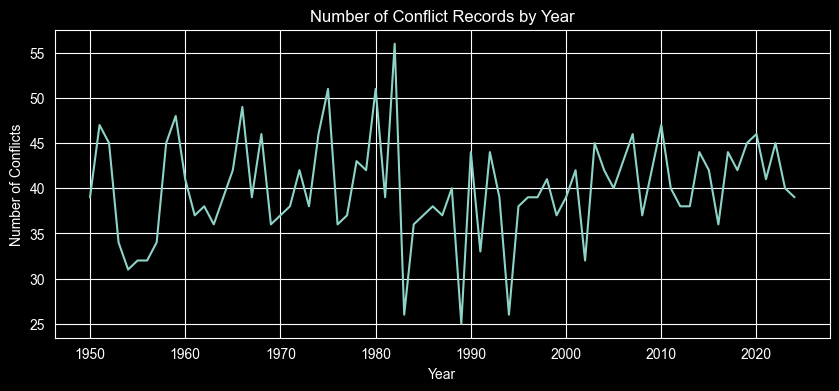

In [19]:
df.groupby('Year').size().plot(figsize=(10,4))
plt.title('Number of Conflict Records by Year')
plt.xlabel('Year')
plt.ylabel('Number of Conflicts')
plt.show()

#### Conflict Characteristics

In [20]:
print('Country_A:', df['Country_A'].nunique())
print('Country_B:', df['Country_B'].nunique())

print(df['Country_A'].value_counts().head(20))
print(df['Country_B'].value_counts().head(20))

Country_A: 15
Country_B: 15
Country_A
USA          224
Ukraine      216
Canada       209
UK           208
Russia       205
Israel       205
Turkey       201
Brazil       200
Iran         199
China        196
Japan        194
France       193
Germany      192
India        181
Australia    177
Name: count, dtype: int64
Country_B
India        217
Germany      213
Ukraine      212
UK           211
Russia       210
USA          208
Japan        208
Brazil       205
China        195
Israel       195
Australia    193
Iran         187
France       184
Turkey       184
Canada       178
Name: count, dtype: int64


In [21]:
## conflict types and duration
df.groupby('Conflict_Type')['Duration_Days'].median()

Conflict_Type
Civil War        1053.0
Cold Conflict    1033.5
Proxy War         984.0
Skirmish          947.0
War              1002.0
Name: Duration_Days, dtype: float64

<Axes: xlabel='Conflict_Type'>

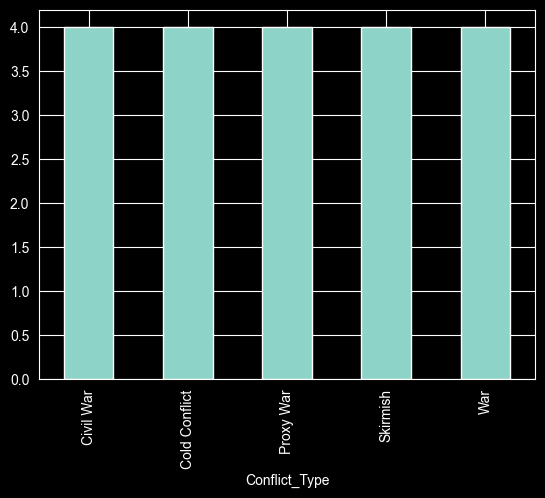

In [22]:
df.groupby('Conflict_Type')['Weapons_Used'].nunique().plot(kind='bar')

In [23]:
pd.crosstab(
    df['Conflict_Type'],
    df['Weapons_Used'],
    normalize='index'
)

Weapons_Used,Conventional,Cyber,Mixed,Nuclear
Conflict_Type,,,,
Civil War,0.231156,0.232831,0.244556,0.291457
Cold Conflict,0.256803,0.255102,0.234694,0.253401
Proxy War,0.254428,0.276973,0.228663,0.239936
Skirmish,0.250399,0.237640,0.236045,0.275917
War,0.253968,0.266314,0.261023,0.218695


## Association Between Conflict Type and Weapons Used

To investigate whether conflict type and weapons used are associated,
a chi-square test of independence is performed.

Both variables are categorical:

- `Conflict_Type` identifies the type of conflict.
- `Weapons_Used` identifies the weapons used.

### Hypotheses

- **Null hypothesis (H₀):** Conflict type and weapons used are independent.
- **Alternative hypothesis (H₁):** Conflict type and weapons used are associated.

A significance level of 0.05 is used.

In [24]:
# is there an association between conflict type and the type of weapons used?
from scipy.stats import chi2_contingency

table = pd.crosstab(
    df['Conflict_Type'],
    df['Weapons_Used']
)

chi2, p_value, dof, expected = chi2_contingency(table)
print("Chi-square:", chi2)
print("p-value:", p_value)

if p_value < 0.05:
    print("Reject H₀: there is evidence of an association.")
else:
    print("Fail to reject H₀: there is insufficient evidence of an association.")
# The p-value is below 0.05. Therefore, the null hypothesis is rejected.

Chi-square: 13.532219473642556
p-value: 0.3315709738655536
Fail to reject H₀: there is insufficient evidence of an association.


In [25]:
# how many naval battles are associated with each conflict type
naval_battles = df.groupby('Conflict_Type')['Naval_Battles'].sum()
naval_battles

Conflict_Type
Civil War        58080
Cold Conflict    57020
Proxy War        60849
Skirmish         63316
War              57284
Name: Naval_Battles, dtype: int64

In [26]:
## type of outcome
# df['Refugees_Millions'].value_counts().plot(kind='bar')
df['Outcome'].value_counts()

Outcome
Victory_A    1003
Victory_B    1002
Stalemate     995
Name: count, dtype: int64

In [27]:
df[['Alliance_A', 'Alliance_B', 'Resource_Dispute']] = (
    df[['Alliance_A', 'Alliance_B', 'Resource_Dispute']]
    .fillna("Unknown")
)

In [28]:
print(df['Alliance_A'].value_counts(dropna=False))
print(df['Alliance_B'].value_counts(dropna=False))
print(df['Resource_Dispute'].value_counts(dropna=False))

Alliance_A
Regional    1039
Unknown      983
NATO         978
Name: count, dtype: int64
Alliance_B
NATO        1024
Unknown      992
Regional     984
Name: count, dtype: int64
Resource_Dispute
Oil        767
Land       745
Unknown    745
Water      743
Name: count, dtype: int64


In [29]:
total_deaths = (
    df['Military_Deaths_A']
    + df['Military_Deaths_B']
    + df['Civilian_Deaths']
)
total_deaths

0       124866
1       214145
2        42140
3       127492
4       142366
         ...  
2995     73070
2996    176056
2997     24876
2998    209331
2999    116124
Length: 3000, dtype: int64

In [30]:
df['Country_A'].nunique(), df['Country_B'].nunique(), df['Year'].nunique()

(15, 15, 75)

In [31]:
df[['Country_A', 'Country_B', 'Year']].duplicated().sum()

np.int64(247)

In [32]:
same_country = df['Country_A'] == df['Country_B']

print("Same-country rows:", same_country.sum())
print("Percentage:", same_country.mean() * 100)

Same-country rows: 204
Percentage: 6.800000000000001


In [33]:
# 4. What types of conflicts are they?
print(
    pd.crosstab(
        df.loc[df['Country_A'] == df['Country_B'], 'Country_A'],
        df.loc[df['Country_A'] == df['Country_B'], 'Conflict_Type']
    )
)

Conflict_Type  Civil War  Cold Conflict  Proxy War  Skirmish  War
Country_A                                                        
Australia              5              2          1         0    4
Brazil                 2              3          5         2    3
Canada                 2              1          2         1    4
China                  3              0          2         3    2
France                 1              2          2         2    1
Germany                1              6          3         2    4
India                  3              4          4         1    2
Iran                   5              1          2         1    1
Israel                 4              3          4         2    1
Japan                  3              3          3         3    4
Russia                 3              3          1         8    1
Turkey                 2              2          4         0    2
UK                     2              3          4         4    4
USA       

In [34]:
df['Year'].value_counts().sort_index()

Year
1950    39
1951    47
1952    45
1953    34
1954    31
        ..
2020    46
2021    41
2022    45
2023    40
2024    39
Name: count, Length: 75, dtype: int64

In [35]:
df.loc[df['Country_A']==df['Country_B'], 'Conflict_Type'].value_counts(dropna=False
                                                                       )

Conflict_Type
Civil War        45
War              42
Proxy War        41
Cold Conflict    39
Skirmish         37
Name: count, dtype: int64

In [36]:
# check whether country and conflict-type values are consistent
df[['Country_A', 'Country_B', 'Conflict_Type']].sample(20, random_state=42)

,Country_A,Country_B,Conflict_Type
1801,Iran,Brazil,War
1190,Ukraine,Iran,War
1817,India,Israel,Skirmish
251,UK,Iran,Proxy War
2505,Ukraine,Germany,Cold Conflict
1117,Israel,Ukraine,Civil War
1411,Brazil,Turkey,Civil War
2113,Ukraine,France,Civil War
408,USA,Russia,Civil War
2579,Canada,France,Cold Conflict
